## 1. Install and import dependencies
Run the installation cell only if the packages are not already installed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 3.1.1
numpy: 2.5.4


## 2. Configure regional input paths and national output

Specify all regional CSV files for Sweden (SE1–SE4) in `INPUT_CSVS`. The output is a national, interval-level dataset: each MTU interval appears once, with generation aggregated across regions, total estimated lifecycle emissions, and generation-weighted national carbon intensity.

In [2]:
# Regional input files for Sweden
INPUT_CSVS = [
    Path("data/NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
    Path("data/NO2_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
    Path("data/NO3_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
    Path("data/NO4_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
    Path("data/NO5_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv"),
]

TARGET_COUNTRY_NAME = "Norway"
OUTPUT_CSV = Path("data/NO_aggregated_generation_with_estimated_carbon_intensity.csv")

# Source data is expected to use 15-minute intervals.
INTERVAL_HOURS = 0.25

missing_files = [p for p in INPUT_CSVS if not p.exists()]
if missing_files:
    raise FileNotFoundError(
        "The following regional input files were not found:\n"
        + "\n".join(str(p) for p in missing_files)
    )

print(f"Found {len(INPUT_CSVS)} input region files.")
print("National output file:", OUTPUT_CSV.resolve())

Found 5 input region files.
National output file: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\NO_aggregated_generation_with_estimated_carbon_intensity.csv


## 3. Load, combine, and inspect the source data from all regions

In [3]:
df_list = []
required_columns = {"MTU (CET/CEST)", "Area", "Production Type", "Generation (MW)"}

for file_path in INPUT_CSVS:
    if file_path.exists():
        region_df = pd.read_csv(file_path, dtype={"Generation (MW)": "string"})
        missing_columns = required_columns - set(region_df.columns)
        if missing_columns:
            raise ValueError(f"File {file_path} is missing required columns: {sorted(missing_columns)}")
        region_df["Source_File"] = file_path.name
        df_list.append(region_df)

if df_list:
    df = pd.concat(df_list, ignore_index=True)
    print("Total Rows Loaded:", len(df))
    print("Regions / Areas found:", df["Area"].unique().tolist())
    display(df.head())
    display(df["Production Type"].value_counts(dropna=False).rename("row_count").to_frame())
else:
    print("No input data loaded. Check file paths.")

Total Rows Loaded: 3679200
Regions / Areas found: ['BZN|NO1', 'BZN|NO2', 'BZN|NO3', 'BZN|NO4', 'BZN|NO5']


,MTU (CET/CEST),Area,Production Type,Generation (MW),Source_File
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|NO1,Biomass,0.00,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|NO1,Biomass,0.00,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|NO1,Biomass,0.00,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|NO1,Biomass,0.00,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|NO1,Biomass,0.00,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv


,row_count
Production Type,
Biomass,175200
Energy storage,175200
Fossil Brown coal/Lignite,175200
Fossil Coal-derived gas,175200
Fossil Gas,175200
Fossil Hard coal,175200
Fossil Oil,175200
Fossil Oil shale,175200
Fossil Peat,175200


## 4. Define lifecycle emission factors

Lifecycle carbon emission factors for each ENTSO-E generation production type ($gCO_2eq / kWh$).

In [4]:
EMISSION_FACTORS = {
    "Wind Onshore": 11.0,
    "Wind Offshore": 11.0,
    "Solar": 48.0,
    "Nuclear": 12.0,
    "Hydro Run-of-river and pondage": 24.0,
    "Hydro Water Reservoir": 24.0,
    "Biomass": 230.0,
    "Fossil Gas": 490.0,
    "Fossil Coal-derived gas": 490.0,
    "Fossil Brown coal/Lignite": 820.0,
    "Fossil Hard coal": 820.0,
    "Fossil Oil": 650.0,
    "Fossil Oil shale": 650.0,
    "Fossil Peat": 820.0,
    "Geothermal": 24.0,
    "Marine": 24.0,
    "Other renewable": 48.0,
    "Other": 490.0,
    "Waste": 500.0,
}

EXCLUDED_SOURCES = {
    "Energy storage",
    "Hydro Pumped Storage",
}

factor_table = (
    pd.DataFrame(
        [{"Production Type": source, "Lifecycle emission factor (gCO2eq/kWh)": factor}
         for source, factor in EMISSION_FACTORS.items()]
    )
    .sort_values("Production Type")
    .reset_index(drop=True)
)
display(factor_table)

,Production Type,Lifecycle emission factor (gCO2eq/kWh)
0,Biomass,230.0
1,Fossil Brown coal/Lignite,820.0
2,Fossil Coal-derived gas,490.0
3,Fossil Gas,490.0
4,Fossil Hard coal,820.0
5,Fossil Oil,650.0
6,Fossil Oil shale,650.0
7,Fossil Peat,820.0
8,Geothermal,24.0
9,Hydro Run-of-river and pondage,24.0


## 5. Clean generation values and parse interval timestamps

In [5]:
work = df.copy()

# Convert generation values to numeric. Invalid tokens such as "n/e" and "-" become NaN.
work["Generation (MW)"] = pd.to_numeric(
    work["Generation (MW)"].astype("string").str.strip().replace({"": pd.NA, "n/e": pd.NA, "-": pd.NA}),
    errors="coerce"
)

# Split interval strings into start and end timestamps
interval_parts = work["MTU (CET/CEST)"].astype("string").str.split(r"\s+-\s+", n=1, expand=True)
if interval_parts.shape[1] != 2:
    raise ValueError("Could not parse interval column; expected 'start - end' strings.")

work["Interval start"] = pd.to_datetime(interval_parts[0], dayfirst=True, errors="coerce")
work["Interval end"] = pd.to_datetime(interval_parts[1], dayfirst=True, errors="coerce")

work["Lifecycle emission factor (gCO2eq/kWh)"] = work["Production Type"].map(EMISSION_FACTORS)

# Mark rows included in carbon intensity calculations
work["Included in carbon-intensity calculation"] = (
    work["Lifecycle emission factor (gCO2eq/kWh)"].notna()
    & work["Generation (MW)"].notna()
)

print("Rows:", len(work))
print("Invalid/missing generation values:", int(work["Generation (MW)"].isna().sum()))
display(work.head())

Rows: 3679200
Invalid/missing generation values: 2819544


,MTU (CET/CEST),Area,Production Type,Generation (MW),Source_File,Interval start,Interval end,Lifecycle emission factor (gCO2eq/kWh),Included in carbon-intensity calculation
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|NO1,Biomass,0.0,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:00:00,2026-01-01 00:15:00,230.0,True
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|NO1,Biomass,0.0,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:15:00,2026-01-01 00:30:00,230.0,True
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|NO1,Biomass,0.0,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:30:00,2026-01-01 00:45:00,230.0,True
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|NO1,Biomass,0.0,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 00:45:00,2026-01-01 01:00:00,230.0,True
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|NO1,Biomass,0.0,NO1_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv,2026-01-01 01:00:00,2026-01-01 01:15:00,230.0,True


## 6. Calculate emissions for each regional production record

For each included production record, estimated emissions are calculated from average generation power, interval duration, and the lifecycle emission factor.

In [6]:
# Generation (MW) is treated as average power over the 15-minute interval.
work["Generation included (MW)"] = work["Generation (MW)"].where(
    work["Included in carbon-intensity calculation"], 0.0
)

# Convert MW over the interval to MWh, then apply the lifecycle factor.
# tCO2eq = MW * interval_hours * EF(gCO2eq/kWh) / 1000
work["Estimated emissions (tCO2eq per 15 min)"] = (
    work["Generation (MW)"]
    * INTERVAL_HOURS
    * work["Lifecycle emission factor (gCO2eq/kWh)"]
    / 1000.0
)
work.loc[
    ~work["Included in carbon-intensity calculation"],
    "Estimated emissions (tCO2eq per 15 min)"
] = np.nan

# Row-level intensity is the lifecycle factor for that production type.
work["Estimated carbon intensity (gCO2eq/kWh)"] = (
    work["Lifecycle emission factor (gCO2eq/kWh)"].where(
        work["Included in carbon-intensity calculation"], np.nan
    )
)

display(work[[
    "MTU (CET/CEST)", "Area", "Production Type", "Generation (MW)",
    "Lifecycle emission factor (gCO2eq/kWh)",
    "Estimated emissions (tCO2eq per 15 min)"
]].head(10))

,MTU (CET/CEST),Area,Production Type,Generation (MW),Lifecycle emission factor (gCO2eq/kWh),Estimated emissions (tCO2eq per 15 min)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|NO1,Biomass,0.0,230.0,0.0
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|NO1,Biomass,0.0,230.0,0.0
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|NO1,Biomass,0.0,230.0,0.0
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|NO1,Biomass,0.0,230.0,0.0
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|NO1,Biomass,0.0,230.0,0.0
5,01/01/2026 01:15:00 - 01/01/2026 01:30:00,BZN|NO1,Biomass,0.0,230.0,0.0
6,01/01/2026 01:30:00 - 01/01/2026 01:45:00,BZN|NO1,Biomass,0.0,230.0,0.0
7,01/01/2026 01:45:00 - 01/01/2026 02:00:00,BZN|NO1,Biomass,0.0,230.0,0.0
8,01/01/2026 02:00:00 - 01/01/2026 02:15:00,BZN|NO1,Biomass,0.0,230.0,0.0
9,01/01/2026 02:15:00 - 01/01/2026 02:30:00,BZN|NO1,Biomass,0.0,230.0,0.0


In [7]:
# National aggregation: combine all regions and production types for each MTU label.
# Repeated MTU labels are deliberately consolidated into one national interval record.
# The resulting carbon intensity is generation-weighted, not a simple arithmetic mean.
work["Weighted generation x factor"] = (
    work["Generation included (MW)"]
    * work["Lifecycle emission factor (gCO2eq/kWh)"].fillna(0.0)
)

COUNTRY_GROUP_KEYS = ["MTU (CET/CEST)"]

interval_summary = (
    work.groupby(COUNTRY_GROUP_KEYS, dropna=False)
    .agg(
        **{
            "Total generation included (MW)": ("Generation included (MW)", "sum"),
            "Weighted generation x factor": ("Weighted generation x factor", "sum"),
            "Estimated total emissions (tCO2eq per 15 min)": (
                "Estimated emissions (tCO2eq per 15 min)",
                lambda values: values.sum(min_count=1)
            ),
            "Interval start": ("Interval start", "min"),
            "Interval end": ("Interval end", "max"),
            "Number of regions": ("Area", "nunique"),
        }
    )
    .reset_index()
)

# Energy generated during each interval.
interval_summary["Total generation (MWh per 15 min)"] = (
    interval_summary["Total generation included (MW)"] * INTERVAL_HOURS
)

# National generation-weighted lifecycle carbon intensity.
interval_summary["Estimated national carbon intensity (gCO2eq/kWh)"] = np.where(
    interval_summary["Total generation included (MW)"] > 0,
    interval_summary["Weighted generation x factor"]
        / interval_summary["Total generation included (MW)"],
    np.nan
)

interval_summary = interval_summary.drop(columns=["Weighted generation x factor"])
interval_summary = interval_summary.sort_values(
    ["Interval start", "MTU (CET/CEST)"], na_position="last"
).reset_index(drop=True)

print("National intervals:", len(interval_summary))
display(interval_summary.head())

National intervals: 35040


,MTU (CET/CEST),Total generation included (MW),Estimated total emissions (tCO2eq per 15 min),Interval start,Interval end,Number of regions,Total generation (MWh per 15 min),Estimated national carbon intensity (gCO2eq/kWh)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,17355.99,119.116983,2026-01-01 00:00:00,2026-01-01 00:15:00,5,4338.9975,27.452651
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,16890.12,115.566768,2026-01-01 00:15:00,2026-01-01 00:30:00,5,4222.53,27.369081
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,16303.19,111.535547,2026-01-01 00:30:00,2026-01-01 00:45:00,5,4075.7975,27.365331
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,15634.43,107.86918,2026-01-01 00:45:00,2026-01-01 01:00:00,5,3908.6075,27.597854
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,15542.35,108.329072,2026-01-01 01:00:00,2026-01-01 01:15:00,5,3885.5875,27.879715


## 7. Export the national interval-level dataset

The exported CSV contains one row per MTU label. Regional generation and emissions are summed first; national carbon intensity is calculated as a generation-weighted average across all included production sources and regions.

In [8]:
# Define the national CSV schema and column order.
final_output_columns = [
    "MTU (CET/CEST)",
    "Interval start",
    "Interval end",
    "Number of regions",
    "Total generation included (MW)",
    "Total generation (MWh per 15 min)",
    "Estimated total emissions (tCO2eq per 15 min)",
    "Estimated national carbon intensity (gCO2eq/kWh)",
]

result = interval_summary[final_output_columns].copy()

# Ensure the destination directory exists, then export the national aggregate.
OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(OUTPUT_CSV, index=False)

print(f"Saved {len(result):,} national interval records to: {OUTPUT_CSV.resolve()}")
display(result.head(10))

Saved 35,040 national interval records to: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\NO_aggregated_generation_with_estimated_carbon_intensity.csv


,MTU (CET/CEST),Interval start,Interval end,Number of regions,Total generation included (MW),Total generation (MWh per 15 min),Estimated total emissions (tCO2eq per 15 min),Estimated national carbon intensity (gCO2eq/kWh)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,2026-01-01 00:00:00,2026-01-01 00:15:00,5,17355.99,4338.9975,119.116983,27.452651
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,2026-01-01 00:15:00,2026-01-01 00:30:00,5,16890.12,4222.53,115.566768,27.369081
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,2026-01-01 00:30:00,2026-01-01 00:45:00,5,16303.19,4075.7975,111.535547,27.365331
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,2026-01-01 00:45:00,2026-01-01 01:00:00,5,15634.43,3908.6075,107.86918,27.597854
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,2026-01-01 01:00:00,2026-01-01 01:15:00,5,15542.35,3885.5875,108.329072,27.879715
5,01/01/2026 01:15:00 - 01/01/2026 01:30:00,2026-01-01 01:15:00,2026-01-01 01:30:00,5,15002.86,3750.715,104.207445,27.783355
6,01/01/2026 01:30:00 - 01/01/2026 01:45:00,2026-01-01 01:30:00,2026-01-01 01:45:00,5,14531.45,3632.8625,101.727898,28.002133
7,01/01/2026 01:45:00 - 01/01/2026 02:00:00,2026-01-01 01:45:00,2026-01-01 02:00:00,5,14276.25,3569.0625,100.177,28.068155
8,01/01/2026 02:00:00 - 01/01/2026 02:15:00,2026-01-01 02:00:00,2026-01-01 02:15:00,5,14633.83,3658.4575,102.147845,27.921015
9,01/01/2026 02:15:00 - 01/01/2026 02:30:00,2026-01-01 02:15:00,2026-01-01 02:30:00,5,14330.04,3582.51,100.337793,28.007680


## 9. Validation checks

## 8. National aggregation and carbon-intensity calculation

All regional generation records are aggregated by `MTU (CET/CEST)`. For each interval, total included generation and estimated emissions are summed across regions and production types. National carbon intensity is the generation-weighted average:

$$CI_{SE}(t)=\frac{\sum_{r,s}G_{r,s}(t)\times EF_s}{\sum_{r,s}G_{r,s}(t)}$$

where $G_{r,s}(t)$ is generation in MW for region $r$ and source $s$, and $EF_s$ is the lifecycle emission factor in $gCO_2eq/kWh$.

The corresponding interval emissions are:

$$E_{SE}(t)=\sum_{r,s}E_{r,s}(t)$$

The aggregation consolidates identical MTU labels into one national record. If the source files contain two genuinely distinct repeated local-time intervals during a daylight-saving transition but provide no UTC offset or other distinguishing identifier, this notebook cannot distinguish those occurrences; they will be combined under the same MTU label.

In [9]:
# 1) Check national carbon intensity bounds.
known_factors = list(EMISSION_FACTORS.values())
ci = interval_summary["Estimated national carbon intensity (gCO2eq/kWh)"].dropna()
assert ci.empty or (ci.min() >= min(known_factors) - 1e-9)
assert ci.empty or (ci.max() <= max(known_factors) + 1e-9)

# 2) The exported national dataset must contain one record per MTU label.
assert not interval_summary["MTU (CET/CEST)"].duplicated().any()

# 3) Check that national emissions and generation are non-negative where available.
generation = interval_summary["Total generation included (MW)"].dropna()
emissions = interval_summary["Estimated total emissions (tCO2eq per 15 min)"].dropna()
assert (generation >= 0).all()
assert (emissions >= 0).all()

print("All national aggregation validation checks passed.")
print(f"National intervals: {len(interval_summary):,}")
if not ci.empty:
    print(f"Carbon intensity min: {ci.min():.2f} gCO2eq/kWh")
    print(f"Carbon intensity median: {ci.median():.2f} gCO2eq/kWh")
    print(f"Carbon intensity max: {ci.max():.2f} gCO2eq/kWh")

All national aggregation validation checks passed.
National intervals: 35,040
Carbon intensity min: 23.52 gCO2eq/kWh
Carbon intensity median: 28.31 gCO2eq/kWh
Carbon intensity max: 35.98 gCO2eq/kWh


## 10. Descriptive statistics and regional/source contributions

In [10]:
# National carbon-intensity descriptive statistics.
display(
    interval_summary["Estimated national carbon intensity (gCO2eq/kWh)"]
    .describe()
    .to_frame()
)

# National generation and emissions totals by interval are available in interval_summary.
display(interval_summary[[
    "Total generation (MWh per 15 min)",
    "Estimated total emissions (tCO2eq per 15 min)",
]].describe())

,Estimated national carbon intensity (gCO2eq/kWh)
count,27128.000000
mean,28.532618
std,1.846510
min,23.521693
25%,27.177061
50%,28.313177
75%,29.669775
max,35.983695


,Total generation (MWh per 15 min),Estimated total emissions (tCO2eq per 15 min)
count,35040.0,27128.0
mean,3107.157481,113.089471
std,1911.606859,24.369349
min,0.0,62.604228
25%,2437.591875,93.441232
50%,3520.17625,111.06506
75%,4402.056875,128.223398
max,6761.6875,177.15213


In [11]:
# National carbon-intensity descriptive statistics.
display(
    interval_summary["Estimated national carbon intensity (gCO2eq/kWh)"]
    .describe()
    .to_frame()
)

# National generation and emissions totals by interval are available in interval_summary.
display(interval_summary[[
    "Total generation (MWh per 15 min)",
    "Estimated total emissions (tCO2eq per 15 min)",
]].describe())

,Estimated national carbon intensity (gCO2eq/kWh)
count,27128.000000
mean,28.532618
std,1.846510
min,23.521693
25%,27.177061
50%,28.313177
75%,29.669775
max,35.983695


,Total generation (MWh per 15 min),Estimated total emissions (tCO2eq per 15 min)
count,35040.0,27128.0
mean,3107.157481,113.089471
std,1911.606859,24.369349
min,0.0,62.604228
25%,2437.591875,93.441232
50%,3520.17625,111.06506
75%,4402.056875,128.223398
max,6761.6875,177.15213


## 11. Plot the estimated target country carbon intensity over time

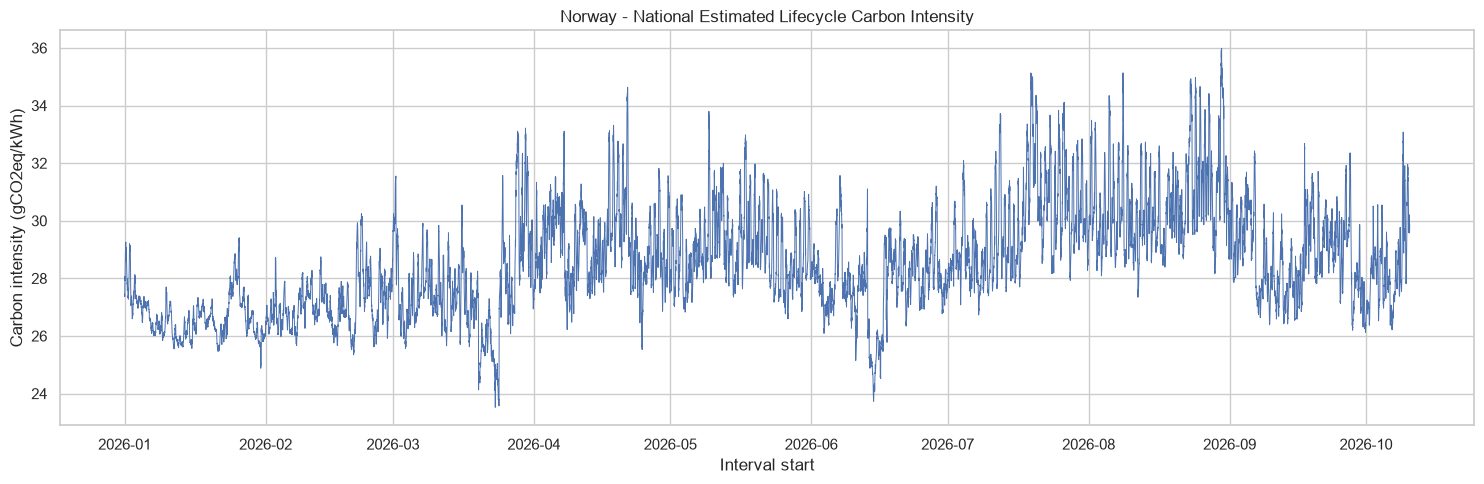

In [12]:
plot_data = interval_summary.dropna(
    subset=["Interval start", "Estimated national carbon intensity (gCO2eq/kWh)"]
).sort_values("Interval start")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    plot_data["Interval start"],
    plot_data["Estimated national carbon intensity (gCO2eq/kWh)"],
    linewidth=0.7,
)
ax.set_title(
    f"{TARGET_COUNTRY_NAME} - National Estimated Lifecycle Carbon Intensity"
)
ax.set_xlabel("Interval start")
ax.set_ylabel("Carbon intensity (gCO2eq/kWh)")
fig.tight_layout()
plt.show()